In [1]:
%load_ext autoreload
%autoreload 2

# Binned background template by NF integration: component 01, 511 keV window

**Goal.** Build a binned background template without sampling events. For each CDS bin $B_i$ the template value is the probability

$$P_i = \int_{B_i} p(E_m, \phi, \chi, \psi)\; dE_m\, d\phi\, d\Omega ,$$

where $p$ is the normalizing-flow (NF) density of Pascal's time-independent model. The expected counts are $N_i = R\,T\,P_i$, with $R\,T$ the number of events behind the model. Integrating instead of sampling avoids Monte Carlo noise in the ~184k bins of a full CDS. The integration error must stay well below the Poisson error $1/\sqrt{N_i}$ of each bin.

**Test case.** Part 01 (provisionally the cosmic-photon / EGB component) in the 511 keV window:

| axis | range | binning |
|---|---|---|
| measured energy $E_m$ | 508–513 keV | 1 bin (provisional) |
| Compton scattering angle $\phi$ | 0–180° | 60 × 3° |
| scattered direction $(\chi, \psi)$, spacecraft frame | full sky | HEALPix NSIDE 16 (3072 px) |

Target template shape: (1, 60, 3072).

**Conventions** (checked against cosipy):
- density units: keV⁻¹ rad⁻¹ sr⁻¹;
- argument order of `evaluate_density`: `(context, Em [keV], phi [rad], chi [rad], psi [rad])`; the context is ignored and only sets the number of points;
- $\chi$ = longitude (`Chi local`), $\psi$ = colatitude (`Psi local`), both in the spacecraft frame;
- $d\Omega = d\cos\psi\, d\chi$, so all sky integrals are done in $u = \cos\psi$ and $\chi$.

**Plan of the notebook.**

| section | what | role |
|---|---|---|
| 2 | load the NF | density evaluated in this process |
| 3 | quadrature tools | shared by all integrals |
| 4 | $P_\text{window}$ | normalization of the template |
| 5 | simulated and NF-sampled events in the window | references for all comparisons |
| 6 | $\phi$ profile $P_k$ | 1D projection, compared with both references |
| 7 | angular marginals in $\cos\psi$ and $\chi$ | quick-look 1D sky projections, compared with both references |
| 8 | template rows $P[p, j]$ for test pixels | how many sky nodes per HEALPix pixel |

Every comparison shows the NF integral against **the simulation** (tests the model) and against **events sampled from the same NF** (the model cancels, so this tests the integration).

**Cost.** One density evaluation is the unit of cost: about **7,000 evaluations/s** on CPU (`batch_size` does not change this). Top to bottom with the default switches takes about 10 min, most of it reading the event files. The two slow tests (4.2, ~8 min; 8.3, ~16 min) are off by default and their results are recorded in the text.

## 1. Setup

### 1.1 Imports

The last lines apply the project plot style from `src/plot_style.py`; it must come after the cosipy import, which installs its own style. Colors come from `COLORS`: `"nf"` purple (NF integral), `"sim"` black, `"nf_samples"` red, `"ref"` gray.

In [2]:
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import healpy as hp
import h5py
from astropy.io import fits

from cosipy.background_estimation.ml import NFBackground
from cosipy.background_estimation.ml.NFBackgroundModels import BackgroundDensityECDFSplineDGaussianARQSFlow

sys.path.insert(0, str(Path.cwd().parent))   # project root, so `src` is importable
from src.plot_style import COLORS, set_global_style
set_global_style()

# Must stay after the cosipy import: threeML (imported by cosipy) switches matplotlib to the
# non-interactive Agg backend when no DISPLAY is set, and then plt.show() draws nothing.
%matplotlib inline


WARNING FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.



### 1.2 Configuration

All paths, the energy window, the binning, and the switches for the two slow tests. The simulated file is the uncompressed copy made in notebook 06; the NF samples were drawn in notebook 06.

In [3]:
# Inputs
MODEL_PATH = Path("../model/nfbackground_part-01_v3-00.fits")
SIM_PATH = Path("../data/background_components/"
                "CosmicPhotons_3months_unbinned_data_filtered_with_SAAcut.fits")
NF_SAMPLES_PATH = Path("../data/NF_background/part-01_full_caffeinated.hdf5")

# 511 keV test window
E_LO, E_LINE, E_HI = 508.0, 511.0, 513.0   # keV; the Em quadrature is split at E_LINE
PHI_EDGES_DEG = np.arange(0, 181, 3)       # 60 x 3 deg phi bins
NSIDE = 16                                 # HEALPix sky bins, NESTED ordering: 3072 pixels

# Switches for the slow tests (results recorded in the text)
RUN_CONVERGENCE = False     # Section 4.2: ~3.5 M evaluations, ~8 min
RUN_SUBPIXEL_TEST = False   # Section 8.3: ~5.2 M evaluations, ~16 min

CHUNK = 1_000_000           # rows per read when scanning the event files

## 2. Load the NF model

`NFBackground` reads the checkpoint. Without the `devices` argument it starts no worker pool, which keeps COSIpy multiprocessing out of the notebook kernel. The density network is built directly from the checkpoint as `dens_model`, so it can be evaluated on arbitrary points in this process.

`N_total` is the event count stored with the model's rate ($R\,T$). It converts probabilities into expected counts.

In [4]:
nfb = NFBackground(MODEL_PATH, density_compile_mode=None, show_progress=False)   # no devices -> no pool
dens_model = BackgroundDensityECDFSplineDGaussianARQSFlow(
    nfb._density_input, "cpu", 100_000, None)   # (density_input, device, batch_size, compile_mode)

N_total = nfb._ckpt["rate_input"]["counts"]     # R*T

print("model version:", nfb._version, "| worker pool active:", nfb.active_pool)
print("Em cuts [keV]:", dens_model._menergy_cuts, "| phi cuts [rad]:", dens_model._phi_cuts)
print(f"R*T = {N_total:,} events")

model version: 3.00 | worker pool active: False
Em cuts [keV]: [100, 10000] | phi cuts [rad]: [0.0, 3.141592653589793]
R*T = 97,554,902 events


### 2.1 Sanity check: density at five points

Confirms the argument order and the order of magnitude. Expected values: about $3\times10^{-6}$ to $4\times10^{-5}$ keV⁻¹ rad⁻¹ sr⁻¹.

In [5]:
Em  = torch.tensor([510.0, 510.0, 510.0, 509.0, 512.0], dtype=torch.float64)                # keV
phi = torch.deg2rad(torch.tensor([20.0, 45.0, 90.0, 30.0, 60.0], dtype=torch.float64))
chi = torch.deg2rad(torch.tensor([0.0, 90.0, 180.0, 270.0, 45.0], dtype=torch.float64))     # longitude
psi = torch.deg2rad(torch.tensor([30.0, 60.0, 90.0, 120.0, 150.0], dtype=torch.float64))   # colatitude

dens = dens_model.evaluate_density(torch.zeros_like(Em), Em, phi, chi, psi)

print(f"{'Em[keV]':>8} {'phi[deg]':>9} {'chi[deg]':>9} {'psi[deg]':>9} {'density [keV^-1 rad^-1 sr^-1]':>30}")
for e, p, c, s, d in zip(Em, phi, chi, psi, dens):
    print(f"{e:8.1f} {np.rad2deg(p):9.1f} {np.rad2deg(c):9.1f} {np.rad2deg(s):9.1f} {d.item():30.4e}")

 Em[keV]  phi[deg]  chi[deg]  psi[deg]  density [keV^-1 rad^-1 sr^-1]
   510.0      20.0       0.0      30.0                     5.4986e-06
   510.0      45.0      90.0      60.0                     1.8144e-05
   510.0      90.0     180.0      90.0                     3.9404e-05
   509.0      30.0     270.0     120.0                     3.2492e-06
   512.0      60.0      45.0     150.0                     5.9328e-06



WARNING DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)



## 3. Quadrature tools

Every integral in Sections 4–7 is a weighted sum of the density on a tensor-product grid $E_m \times \phi \times u \times \chi$. The node rules per axis:

| axis | rule | why |
|---|---|---|
| $E_m$ | Gauss–Legendre, split at 511 keV | the density peaks at the line; splitting there keeps each piece smooth (same idea as cosipy's `NFBkgNormalizationMap`) |
| $\phi$ | Gauss–Legendre on $[0, \pi]$, or `n_per_bin` GL nodes inside each 3° bin | per-bin nodes respect the bin edges exactly |
| $u = \cos\psi$ | Gauss–Legendre, or uniform midpoints for fine marginals | uniform in $u$ means uniform in solid angle |
| $\chi$ | uniform midpoints on $[0, 2\pi)$ | very accurate for smooth periodic functions |

`density_grid` evaluates the density on the full grid and returns a 4D array, so an integral over any subset of axes is one `np.einsum`. The HEALPix sky nodes used for the template rows are defined in Section 8.

In [6]:
def gl(a, b, n):
    # Gauss-Legendre nodes and weights on [a, b].
    x, w = np.polynomial.legendre.leggauss(n)
    return 0.5*(b - a)*x + 0.5*(b + a), 0.5*(b - a)*w


def uniform_nodes(a, b, n):
    # Midpoints of n equal bins on [a, b], weight = bin width.
    h = (b - a) / n
    return a + (np.arange(n) + 0.5) * h, np.full(n, h)


def energy_nodes(n_per_side):
    # GL nodes in Em on [E_LO, E_HI], split at the line: n_per_side nodes on each side.
    e1, w1 = gl(E_LO, E_LINE, n_per_side)
    e2, w2 = gl(E_LINE, E_HI, n_per_side)
    return np.concatenate([e1, e2]), np.concatenate([w1, w2])


def phi_nodes(n_per_bin, phi_edges_deg=PHI_EDGES_DEG):
    # n_per_bin GL nodes and weights inside each phi bin [rad], bin after bin.
    edges = np.deg2rad(phi_edges_deg)
    return map(np.concatenate, zip(*[gl(a, b, n_per_bin) for a, b in zip(edges[:-1], edges[1:])]))


def density_grid(E, P, U, C):
    # NF density on the grid E x P x U x C -> array of shape (len(E), len(P), len(U), len(C)).
    # E: Em [keV], P: phi [rad], U: cos(colatitude), C: longitude chi [rad].
    Em, phi, u, chi = [torch.as_tensor(a.ravel(), dtype=torch.float64)
                       for a in np.meshgrid(E, P, U, C, indexing="ij")]
    dens = dens_model.evaluate_density(torch.zeros_like(Em), Em, phi, chi, torch.arccos(u))
    return dens.numpy().astype(np.float64).reshape(len(E), len(P), len(U), len(C))

## 4. Total probability in the window

$P_\text{window}$ is the integral over the energy window, all $\phi$, and the full sky. It is the sum of all template bins in this window, so it fixes the normalization: the model expects $R\,T\,P_\text{window}$ events in 508–513 keV.

### 4.1 Base resolution

16 nodes per side in $E_m$ and 24 in each of $\phi$, $u$, $\chi$: 442k evaluations, about 1 min.

In [7]:
def window_fraction(nE, nphi, ncos, nchi):
    # P_window on a (2*nE) x nphi x ncos x nchi grid. Returns (P_window, number of evaluations).
    E, wE = energy_nodes(nE)
    P, wP = gl(0.0, np.pi, nphi)
    U, wU = gl(-1.0, 1.0, ncos)
    C, wC = uniform_nodes(0.0, 2*np.pi, nchi)
    dens = density_grid(E, P, U, C)
    return float(np.einsum("ijkl,i,j,k,l->", dens, wE, wP, wU, wC)), dens.size


P_window, n_eval = window_fraction(16, 24, 24, 24)
print(f"P_window = {P_window:.6e}   ({n_eval:,} evaluations)")
print(f"expected events in the window: R*T*P_window = {N_total * P_window:,.0f}")

P_window = 2.060676e-03   (442,368 evaluations)
expected events in the window: R*T*P_window = 201,029


### 4.2 Convergence test (off by default)

Double the number of nodes on one axis at a time and compare with the base value. Set `RUN_CONVERGENCE = True` in 1.2 to rerun (~8 min).

**Recorded result (2026-11-10):** base $P_\text{window} = 2.060675\times10^{-3}$ (a coarser 8/16/16/16 grid gave $2.010984\times10^{-3}$, 2.4% lower).

| axis doubled | nodes (Em per side, φ, cos ψ, χ) | $P_\text{window}$ | change vs base |
|---|---|---|---|
| $E_m$ | (32, 24, 24, 24) | 2.060657e-03 | −8.7e-06 |
| $\phi$ | (16, 48, 24, 24) | 2.053528e-03 | −3.5e-03 |
| $\cos\psi$ | (16, 24, 48, 24) | 2.067322e-03 | +3.2e-03 |
| $\chi$ | (16, 24, 24, 48) | 2.068842e-03 | +4.0e-03 |

$E_m$ is converged. The three angular axes each still move the result by ~0.3–0.4%, so the density has angular structure that 24 nodes do not fully resolve. Best estimate: $P_\text{window} \approx 2.07\times10^{-3}$, uncertain at the ~0.5% level.

In [8]:
if RUN_CONVERGENCE:
    base = (16, 24, 24, 24)
    for i, name in enumerate(["Em per side", "phi", "cos(colat)", "chi"]):
        res = list(base)
        res[i] *= 2
        P2, n = window_fraction(*res)
        print(f"double {name:12s} {tuple(res)}: {n:>9,d} evals -> P = {P2:.6e}, "
              f"change vs base = {(P2 - P_window) / P_window:+.2e}")
else:
    print("Skipped (RUN_CONVERGENCE = False); see the recorded table above.")

Skipped (RUN_CONVERGENCE = False); see the recorded table above.


## 5. Reference events in the window

Two event sets are read and cut to the energy window, keeping the three angles needed for the comparisons (keV and rad; `Psi local` is the colatitude in both files):

- **Simulation** (`SIM_PATH`, 10.9 GB, read through a memory map): about 200k events in the window, a few minutes. The file holds as many events as the model's `counts` (97,554,902), so it is very likely the NF training sample: the comparison tests how well the flow reproduces its own training data.
- **NF samples** (`NF_SAMPLES_PATH`): 97,554,902 events drawn in notebook 06 from the same part 01 model. About 1.5 GB is read, about a minute.

The printed angle ranges must be about $[0, \pi]$ for `Phi` and `Psi local` and $[0, 2\pi)$ for `Chi local`.

In [9]:
def read_window(n_rows, read_column, columns=("Phi", "Chi local", "Psi local")):
    # Scan a file in CHUNK rows and keep `columns` of the events with E_LO <= Energies < E_HI.
    # read_column(name, start, stop) returns rows start:stop of one column.
    sel = {k: [] for k in columns}
    for a in range(0, n_rows, CHUNK):
        energy = read_column("Energies", a, a + CHUNK)
        in_window = (energy >= E_LO) & (energy < E_HI)
        for k in columns:
            sel[k].append(read_column(k, a, a + CHUNK)[in_window])
    return {k: np.concatenate(v).astype(np.float64) for k, v in sel.items()}


with fits.open(SIM_PATH, memmap=True) as hdul:
    ev = hdul[1].data
    N_sim_total = len(ev)
    sim = read_window(N_sim_total, lambda k, a, b: ev[k][a:b])

with h5py.File(NF_SAMPLES_PATH, "r") as f:
    print("NF samples: model file", f.attrs["model_file"],
          "| completed samples:", f"{f.attrs['completed_samples']:,}")
    N_nf_total = f["Energies"].shape[0]
    nf_samp = read_window(N_nf_total, lambda k, a, b: f[k][a:b])

for label, events, n_file in (("simulation", sim, N_sim_total), ("NF samples", nf_samp, N_nf_total)):
    print(f"\n{label}: {n_file:,} events in file (model R*T: {N_total:,}), "
          f"{len(events['Phi']):,} in {E_LO:.0f}-{E_HI:.0f} keV")
    for k, v in events.items():
        print(f"  {k:10s} range [{v.min():.3f}, {v.max():.3f}] rad")

NF samples: model file nfbackground_part-01_v3-00.fits | completed samples: 97,554,902

simulation: 97,554,902 events in file (model R*T: 97,554,902), 202,956 in 508-513 keV
  Phi        range [0.197, 3.136] rad
  Chi local  range [0.000, 6.283] rad
  Psi local  range [0.000, 3.142] rad

NF samples: 97,554,902 events in file (model R*T: 97,554,902), 201,990 in 508-513 keV
  Phi        range [0.195, 3.137] rad
  Chi local  range [0.000, 6.283] rad
  Psi local  range [0.004, 3.140] rad


### 5.1 Comparison helper

`compare_with_events` histograms both event sets on the bin edges of an NF projection and draws two columns: NF integral vs **simulation** (left) and NF integral vs **NF samples** (right). Each column shows the counts (points with $\sqrt{N}$ errors) against the NF expectation (steps, $R\,T$ times the probability per bin), and below it the Pearson residual $(N - N_\text{NF})/\sqrt{N_\text{NF}}$.

Without a mismatch the Pearson residuals scatter around 0 with unit width and $\chi^2/\text{ndf} \approx 1$ ($\chi^2$ = sum of their squares over bins with more than 5 expected counts). Reading the two columns together: the right column measures the integration, the left column the model plus the integration.

In [10]:
def plot_vs_model(ax, rx, edges, counts, mod_counts, xlabel, data_label, data_color):
    # Upper axis: event counts and NF expectation. Lower axis: Pearson residuals. Returns (chi2, ndf).
    centers = 0.5 * (edges[1:] + edges[:-1])
    ax.stairs(mod_counts, edges, color=COLORS["nf"], label="NF integral")
    ax.errorbar(centers, counts, yerr=np.sqrt(counts), fmt="o", ms=2.5, lw=1.0,
                color=data_color, label=data_label)
    ax.set_ylabel("counts / bin")
    ax.legend()

    pearson = (counts - mod_counts) / np.sqrt(np.where(mod_counts > 0, mod_counts, np.nan))
    rx.stairs(pearson, edges, baseline=None, color=COLORS["nf"])
    rx.axhline(0, color=COLORS["ref"], lw=1.0)
    for s in (-2, 2):
        rx.axhline(s, color=COLORS["ref"], ls=":", lw=1.0)
    rx.set_ylabel(r"Pearson [$\sigma$]")
    rx.set_xlabel(xlabel)

    ok = mod_counts > 5
    return np.sum(pearson[ok] ** 2), ok.sum()


def compare_with_events(P_bins, edges, variable, xlabel, plot_edges=None):
    # P_bins: NF probability per bin on `edges`; variable(events) maps an event dict to the binned quantity.
    # plot_edges: edges in display units (default: edges).
    plot_edges = edges if plot_edges is None else plot_edges
    fig, axs = plt.subplots(2, 2, figsize=(16, 8), sharex=True,
                            gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05, "wspace": 0.3})
    refs = (("simulation", sim, N_total, COLORS["sim"]),
            ("NF samples", nf_samp, N_nf_total, COLORS["nf_samples"]))
    for c, (label, events, n_tot, color) in enumerate(refs):
        counts, _ = np.histogram(variable(events), bins=edges)
        model = n_tot * P_bins
        chi2, ndf = plot_vs_model(axs[0, c], axs[1, c], plot_edges, counts, model, xlabel, label, color)
        axs[0, c].set_title(rf"NF integral vs {label}:  $\chi^2$/ndf = {chi2:.0f}/{ndf}")
        print(f"{label:<11} total {counts.sum():,} vs NF integral {model.sum():,.0f} "
              f"({counts.sum() / model.sum() - 1:+.2%}; Poisson 1 sigma = {1 / np.sqrt(counts.sum()):.2%})")
    plt.show()

## 6. $\phi$ profile: $P_k$ per 3° bin

Each $\phi$ bin gets its own `n_per_bin` Gauss–Legendre nodes, so the bin edges are respected exactly; the result is integrated over $E_m$ and the full sky. $\sum_k P_k$ must agree with $P_\text{window}$. About 983k evaluations, ~2.5 min.

The window total is the sharpest single number: with ~200k events its Poisson error is ~0.2%, comparable to the integration error (4.2).

In [11]:
def phi_profile(nE=8, n_per_bin=4, ncos=16, nchi=16):
    # P_k for each phi bin: integral over the window, the bin, and the full sky.
    E, wE = energy_nodes(nE)
    P, wP = phi_nodes(n_per_bin)
    U, wU = gl(-1.0, 1.0, ncos)
    C, wC = uniform_nodes(0.0, 2*np.pi, nchi)
    dens = density_grid(E, P, U, C)
    per_node = np.einsum("ijkl,i,j,k,l->j", dens, wE, wP, wU, wC)
    return per_node.reshape(-1, n_per_bin).sum(axis=1)


P_k = phi_profile()
print(f"sum of P_k = {P_k.sum():.6e}   vs P_window = {P_window:.6e} "
      f"({P_k.sum() / P_window - 1:+.2%})")

sum of P_k = 2.065657e-03   vs P_window = 2.060676e-03 (+0.24%)


**Recorded result (2026-11-11):** $\sum_k P_k = 2.0657\times10^{-3}$ (+0.24% vs $P_\text{window}$).

| | window total vs NF integral | $\chi^2$/ndf |
|---|---|---|
| simulation | 202,956 vs 201,515 (+0.72%, 1σ = 0.22%) | 94/57 |
| NF samples | 201,990 vs 201,515 (+0.24%, 1σ = 0.22%) | 73/57 |

The profile has sharp edges near 15°, 57° and 90°; the largest residuals sit in the bins at these edges (up to ~5σ in 12–15° for the samples).


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



simulation  total 202,956 vs NF integral 201,515 (+0.72%; Poisson 1 sigma = 0.22%)
NF samples  total 201,990 vs NF integral 201,515 (+0.24%; Poisson 1 sigma = 0.22%)


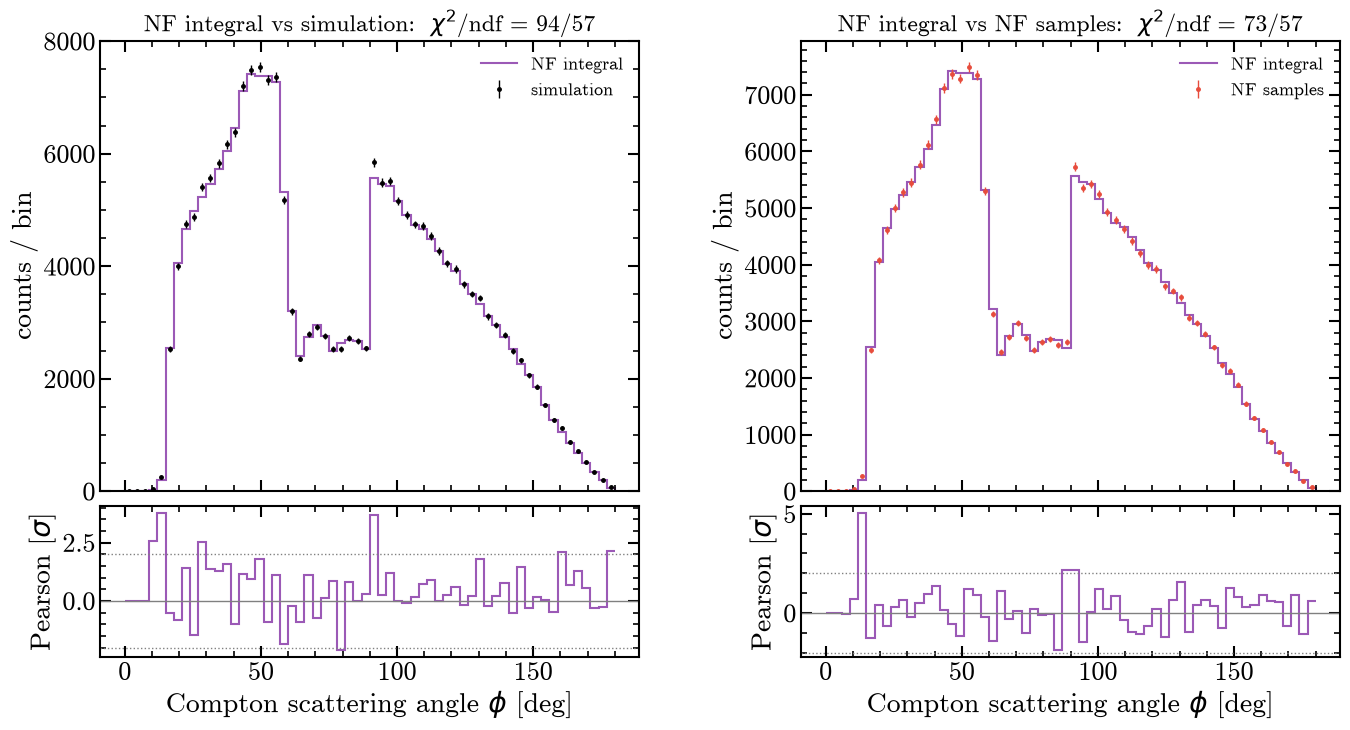

In [12]:
compare_with_events(P_k, PHI_EDGES_DEG, lambda ev: np.rad2deg(ev["Phi"]),
                    r"Compton scattering angle $\phi$ [deg]")

## 7. Angular marginals: $dP/d\cos\psi$ and $dP/d\chi$ (quick look)

Integrate over $E_m$, $\phi$, and one sky axis, and keep the other on 180 uniform bins (one midpoint node per bin). The output is a density per unit of that variable on known bin edges. The simulation and the samples are histogrammed on the same edges; `Chi local` is wrapped to $[0, 2\pi)$.

This quick look uses 12 nodes in $\phi$ and in the other sky axis (~210k evaluations per marginal, ~1 min in total); the defaults `nphi=24, n_other=24` take ~4 min.

**Recorded result (2026-11-11, 12 nodes):** the marginals integrate to $2.31\times10^{-3}$ ($\cos\psi$) and $2.18\times10^{-3}$ ($\chi$), i.e. +12% and +6% above $P_\text{window}$, so this quadrature is not accurate enough for the normalization.

| | colatitude $\chi^2$/ndf | longitude $\chi^2$/ndf |
|---|---|---|
| simulation | 2698/180 | 14714/180 |
| NF samples | 2811/180 | 731/180 |

- **Colatitude:** the NF samples show the same excess of the integral at $\cos\psi > 0$ as the simulation, so it comes from the quick-look integration, not from the model.
- **Longitude:** against the samples the difference is mostly the ~6% normalization offset. Against the simulation there are narrow spikes and dips every few degrees that the NF does not have; the training data were blurred by 5° in azimuth because of the detector strip pattern (Pascal's thesis), so this is expected.

In [13]:
def angular_marginal(which, n_fine=180, nE=4, nphi=24, n_other=24):
    # which="cos": dP/dcos(psi) on n_fine uniform bins in cos(psi), chi integrated.
    # which="chi": dP/dchi [1/rad] on n_fine uniform bins in chi, cos(psi) integrated.
    # Returns (bin edges, density per unit of the kept variable).
    E, wE = energy_nodes(nE)
    P, wP = gl(0.0, np.pi, nphi)
    if which == "cos":
        U, wU = uniform_nodes(-1.0, 1.0, n_fine)
        C, wC = uniform_nodes(0.0, 2*np.pi, n_other)
        dens = density_grid(E, P, U, C)
        return np.linspace(-1.0, 1.0, n_fine + 1), np.einsum("ijkl,i,j,l->k", dens, wE, wP, wC)
    if which == "chi":
        U, wU = uniform_nodes(-1.0, 1.0, n_other)
        C, wC = uniform_nodes(0.0, 2*np.pi, n_fine)
        dens = density_grid(E, P, U, C)
        return np.linspace(0.0, 2*np.pi, n_fine + 1), np.einsum("ijkl,i,j,k->l", dens, wE, wP, wU)
    raise ValueError("which must be 'cos' or 'chi'")


cos_edges, dP_dcos = angular_marginal("cos", nphi=12, n_other=12)
chi_edges, dP_dchi = angular_marginal("chi", nphi=12, n_other=12)

print(f"integral of dP/dcos(psi) = {np.sum(dP_dcos * np.diff(cos_edges)):.4e}")
print(f"integral of dP/dchi      = {np.sum(dP_dchi * np.diff(chi_edges)):.4e}")
print(f"P_window                 = {P_window:.4e}")

integral of dP/dcos(psi) = 2.3093e-03
integral of dP/dchi      = 2.1795e-03
P_window                 = 2.0607e-03


simulation  total 202,956 vs NF integral 225,279 (-9.91%; Poisson 1 sigma = 0.22%)
NF samples  total 201,990 vs NF integral 225,279 (-10.34%; Poisson 1 sigma = 0.22%)



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



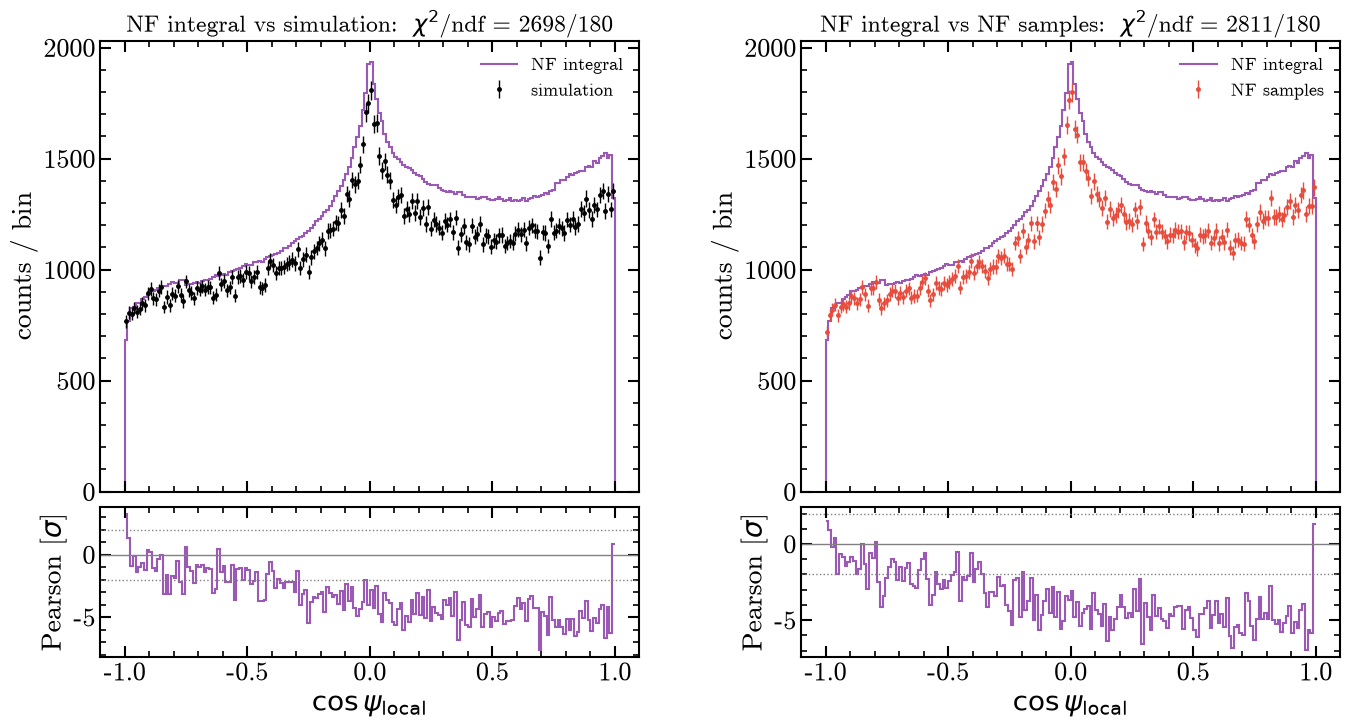

In [14]:
compare_with_events(dP_dcos * np.diff(cos_edges), cos_edges, lambda ev: np.cos(ev["Psi local"]),
                    r"$\cos\psi_{\rm local}$")

simulation  total 202,956 vs NF integral 212,623 (-4.55%; Poisson 1 sigma = 0.22%)
NF samples  total 201,990 vs NF integral 212,623 (-5.00%; Poisson 1 sigma = 0.22%)



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



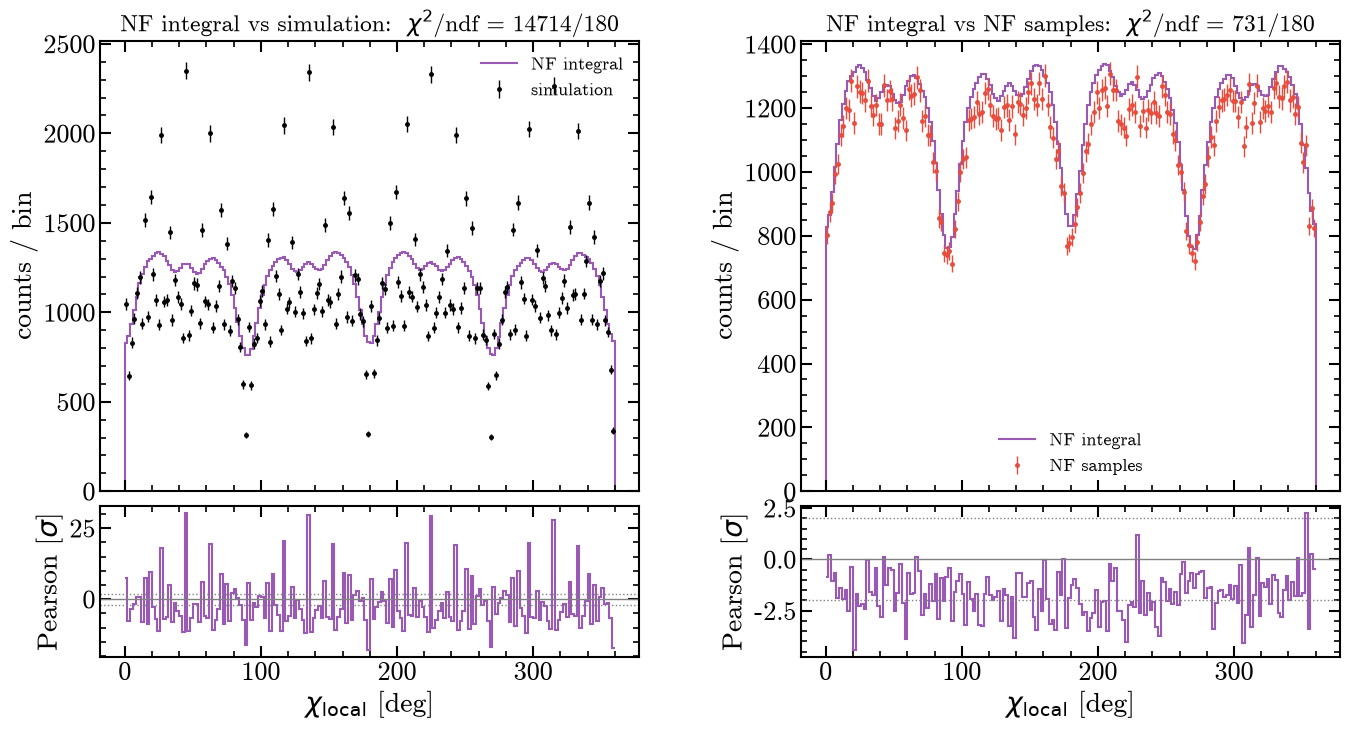

In [15]:
compare_with_events(dP_dchi * np.diff(chi_edges), chi_edges, lambda ev: np.mod(ev["Chi local"], 2*np.pi),
                    r"$\chi_{\rm local}$ [deg]", plot_edges=np.rad2deg(chi_edges))

## 8. Template rows for HEALPix pixels

The template is $P[p, j]$: the integral over the energy window, $\phi$ bin $j$ (60 × 3°) and HEALPix pixel $p$ (NSIDE 16). The tensor grid in $u$ and $\chi$ cannot follow pixel boundaries, so the sky nodes are built from HEALPix itself.

### 8.1 Sky nodes inside each pixel

- Each parent pixel is split into its $4^k$ children at NSIDE $16\cdot 2^k$; in NESTED ordering the children of parent $p$ are $p\,4^k, \dots, p\,4^k + 4^k - 1$.
- The nodes are the child centers (colatitude, longitude in rad), and each weight is the area of one child, $4\pi / (12\,(16\cdot2^k)^2)$ sr.
- The integral of $f$ over a parent pixel is $\sum_\text{children} w\, f(\text{center})$: a midpoint rule on the sphere, so the error should drop by about $4\times$ per step in $k$.

**Test without the NF** ($k = 1, 2$):
- (a) $f = 1$ must give the pixel area $4\pi/3072$ for every pixel. This holds by construction (equal-area pixels); it confirms the weights, not the node positions.
- (b) $f = \cos\psi$ tests the node positions. It must sum to 0 over the full sky. Over the pixels centered north of the equator the exact value is $\pi\,(1 - h^2/3) = 3.139774$, not $\pi$: the 64 pixels centered on the equator straddle it, and leaving them out removes their northern halves (triangles of height $h = 2/(3\cdot\text{NSIDE})$ in $\cos\psi$). The relative error in (b) measures the quadrature itself.

In [16]:
def subpixel_nodes(k, nside=NSIDE):
    # Sky quadrature nodes for every HEALPix pixel (NESTED) at `nside`.
    # Each parent p is split into its 4**k children at nside * 2**k (NESTED indices p*4**k ... p*4**k + 4**k - 1).
    # Returns colatitude [rad], longitude [rad] and weight [sr] of the child centers, each of shape (npix, 4**k).
    npix, n_sub = hp.nside2npix(nside), 4**k
    child = (np.arange(npix)[:, None] * n_sub + np.arange(n_sub)).ravel()
    colat, lon = hp.pix2ang(nside * 2**k, child, nest=True)
    w = np.full(child.size, hp.nside2pixarea(nside * 2**k))  # all HEALPix pixels have the same area
    return colat.reshape(npix, n_sub), lon.reshape(npix, n_sub), w.reshape(npix, n_sub)


npix = hp.nside2npix(NSIDE)                                  # 3072
area = 4*np.pi / npix                                        # sr per parent pixel
theta_c, _ = hp.pix2ang(NSIDE, np.arange(npix), nest=True)   # parent centers, colatitude [rad]
north = np.cos(theta_c) > 1e-12                              # parents centered strictly north of the equator
exact_north = np.pi * (1 - (2 / (3*NSIDE))**2 / 3)           # exact integral of cos over those parents (see text)

for k in (1, 2):
    colat, lon, w = subpixel_nodes(k)
    I_one = w.sum(axis=1)                                    # (a) f = 1          -> pixel area
    I_cos = (w * np.cos(colat)).sum(axis=1)                  # (b) f = cos(colat)
    rel = I_cos[north].sum() / exact_north - 1
    print(f"k={k}: {4**k:2d} nodes/pixel, weight {w[0, 0]:.3e} sr")
    print(f"  (a) max |integral / area - 1| = {np.max(np.abs(I_one / area - 1)):.1e}")
    print(f"  (b) full sky                  = {I_cos.sum():+.2e}   (exact 0)")
    print(f"      north, {north.sum()} pixels       = {I_cos[north].sum():.7f}   "
          f"(exact {exact_north:.7f}, rel. err {rel:+.1e})")

k=1:  4 nodes/pixel, weight 1.023e-03 sr
  (a) max |integral / area - 1| = 0.0e+00
  (b) full sky                  = +4.44e-16   (exact 0)
      north, 1504 pixels       = 3.1398882   (exact 3.1397746, rel. err +3.6e-05)
k=2: 16 nodes/pixel, weight 2.557e-04 sr
  (a) max |integral / area - 1| = 0.0e+00
  (b) full sky                  = +4.44e-16   (exact 0)
      north, 1504 pixels       = 3.1398030   (exact 3.1397746, rel. err +9.0e-06)


### 8.2 Template rows and test pixels

`pixel_template` combines the nodes of the three axes:
- $E_m$: `energy_nodes(4)`, 4 GL nodes on each side of 511 keV ($E_m$ converges easily, 4.2);
- $\phi$: `phi_nodes(4)`, 4 GL nodes inside each 3° bin (as in Section 6);
- sky: the $4^k$ sub-pixel centers of the pixel (8.1).

`density_sky` evaluates the density on $E_m \times \phi \times$ a list of sky points, because the sub-pixel centers are $(\psi, \chi)$ pairs, not a separable grid.

**Test pixels.** Six fixed positions from the north to the south pole, plus the two densest pixels, where errors weigh most in counts. The dense pixels are found from a coarse sky map with one node per pixel (~150k evaluations, ~20 s), used only for this choice.

In [17]:
def density_sky(E, P, colat, lon):
    # NF density on E x P x (list of sky points) -> array of shape (len(E), len(P), len(colat)).
    # colat, lon: paired sky points [rad] (e.g. sub-pixel centers), not a grid.
    Em, phi, s = [a.ravel() for a in np.meshgrid(E, P, np.arange(len(colat)), indexing="ij")]
    Em, phi, psi, chi = [torch.as_tensor(a, dtype=torch.float64) for a in (Em, phi, colat[s], lon[s])]
    dens = dens_model.evaluate_density(torch.zeros_like(Em), Em, phi, chi, psi)
    return dens.numpy().astype(np.float64).reshape(len(E), len(P), len(colat))


def pixel_template(pixels, k, nE=4, n_per_bin=4):
    # Template rows P[p, j] = integral of the density over the window, phi bin j and HEALPix pixel pixels[p]
    # (NESTED), with 4**k sub-pixel nodes per pixel. Returns (array (len(pixels), n_phi_bins), evaluations).
    E, wE = energy_nodes(nE)
    P, wP = phi_nodes(n_per_bin)
    colat, lon, w = (a[pixels] for a in subpixel_nodes(k))         # each (len(pixels), 4**k)
    dens = density_sky(E, P, colat.ravel(), lon.ravel()).reshape(len(E), len(P), len(pixels), -1)
    per_node = np.einsum("ijpq,i,j,pq->pj", dens, wE, wP, w)        # (len(pixels), phi nodes)
    return per_node.reshape(len(pixels), -1, n_per_bin).sum(axis=2), dens.size

In [18]:
# Coarse NF sky map: one node per pixel (its center, k = 0), coarse in Em and phi. Only used to find dense pixels.
E0, wE0 = energy_nodes(2)
P0, wP0 = gl(0.0, np.pi, 12)
colat0, lon0, w0 = subpixel_nodes(0)
coarse_map = np.einsum("ijs,i,j->s", density_sky(E0, P0, colat0[:, 0], lon0[:, 0]), wE0, wP0) * w0[:, 0]
print(f"coarse map: sum = {coarse_map.sum():.4e} (P_window = {P_window:.4e}), "
      f"max/mean = {coarse_map.max() / coarse_map.mean():.1f}")

# Test pixels: fixed positions from pole to pole, plus the two densest pixels of the coarse map.
probes = {"north pole": (2, 45), "north cap": (30, 100), "north belt": (65, 200),
          "equator": (90, 300), "south belt": (115, 20), "south pole": (178, 250)}   # (colat, lon) [deg]
test = {name: hp.ang2pix(NSIDE, np.deg2rad(c), np.deg2rad(l), nest=True) for name, (c, l) in probes.items()}
dense = [q for q in np.argsort(coarse_map)[::-1] if q not in test.values()][:2]
test.update({f"densest {i + 1}": q for i, q in enumerate(dense)})

test_labels, test_pix = list(test), np.array(list(test.values()))
for name, q in test.items():
    c, l = np.rad2deg(hp.pix2ang(NSIDE, q, nest=True))
    print(f"{name:<11} NESTED pixel {q:4d}: center colat {c:6.1f}, lon {l:6.1f} deg, "
          f"coarse P = {coarse_map[q]:.2e}")

coarse map: sum = 2.1947e-03 (P_window = 2.0607e-03), max/mean = 2.1
north pole  NESTED pixel  255: center colat    2.9, lon   45.0 deg, coarse P = 1.47e-06
north cap   NESTED pixel  444: center colat   32.6, lon  102.3 deg, coarse P = 7.55e-07
north belt  NESTED pixel  642: center colat   65.4, lon  199.7 deg, coarse P = 8.52e-07
equator     NESTED pixel 1881: center colat   90.0, lon  300.9 deg, coarse P = 1.16e-06
south belt  NESTED pixel 2238: center colat  114.6, lon   19.7 deg, coarse P = 6.75e-07
south pole  NESTED pixel 2560: center colat  177.1, lon  225.0 deg, coarse P = 6.53e-07
densest 1   NESTED pixel  767: center colat    2.9, lon  225.0 deg, coarse P = 1.53e-06
densest 2   NESTED pixel  511: center colat    2.9, lon  135.0 deg, coarse P = 1.50e-06


### 8.3 How many sub-pixels per pixel? (off by default)

Template rows of the 8 test pixels for $k = 1, 2, 3, 4$ (4 to 256 sub-pixels). $k = 4$ is the reference. For $k = 1, 2, 3$:
- `dTot`: relative change of the pixel total (summed over $\phi$). Errors with the same sign in all pixels add up in the normalization, so they should end up well below the ~0.2% Poisson error of the window total (Section 6).
- `max z`: the largest $|\Delta N_j| / \sqrt{N_j}$ over the $\phi$ bins, with $N_j = R\,T\,P_\text{ref}[p, j]$: the integration error in units of the Poisson error of that bin. It should be $\ll 1$.

Cost: $4^k \times 240 \times 8$ evaluations per $k$, ~5.2M in total, **~16 min** (measured: 8, 38, 158, 738 s). Set `RUN_SUBPIXEL_TEST = True` in 1.2 to rerun.

**Recorded result (2026-11-11):**

| pixel | nest | colat | lon | N_pix | dTot k=1 | max z | dTot k=2 | max z | dTot k=3 | max z |
|---|---|---|---|---|---|---|---|---|---|---|
| north pole | 255 | 2.9 | 45.0 | 74.6 | −6.7e-02 | 1.7e-01 | −1.8e-01 | 4.0e-01 | −8.7e-02 | 2.0e-01 |
| north cap | 444 | 32.6 | 102.3 | 65.9 | +3.8e-04 | 7.0e-03 | +1.5e-04 | 1.3e-03 | +1.2e-05 | 6.5e-04 |
| north belt | 642 | 65.4 | 199.7 | 77.1 | +5.4e-05 | 3.6e-03 | +7.6e-05 | 9.6e-04 | +2.3e-05 | 2.8e-04 |
| equator | 1881 | 90.0 | 300.9 | 104.7 | +1.9e-02 | 1.8e-01 | +2.7e-03 | 5.4e-02 | +4.3e-04 | 1.2e-02 |
| south belt | 2238 | 114.6 | 19.7 | 64.4 | −7.8e-05 | 6.6e-03 | +2.5e-04 | 1.5e-03 | +1.1e-05 | 4.9e-04 |
| south pole | 2560 | 177.1 | 225.0 | 42.0 | −9.8e-02 | 1.3e-01 | −1.8e-01 | 2.3e-01 | −6.3e-02 | 7.7e-02 |
| densest 1 | 767 | 2.9 | 225.0 | 73.7 | −4.2e-02 | 1.1e-01 | −1.8e-01 | 3.9e-01 | −6.9e-02 | 1.5e-01 |
| densest 2 | 511 | 2.9 | 135.0 | 74.4 | −5.4e-02 | 1.2e-01 | −1.8e-01 | 3.9e-01 | −6.9e-02 | 1.5e-01 |

- Away from the poles the rows converge as expected: at $k = 3$, `dTot` ≤ 4e-4 and `max z` ≤ 1e-2 (the equator pixel converges more slowly but steadily).
- The four polar-cap pixels (colatitude 2.9° and 177.1°, which include the two densest pixels) do **not** converge: `dTot` is −4 to −10% at $k=1$, −18% at $k=2$, −6 to −9% at $k=3$, so the error does not fall by 4× per step, and `max z` reaches 0.4. In the plot the low-$\phi$ bins (< 10°) differ by factors 2–3 between $k$.

In [19]:
if RUN_SUBPIXEL_TEST:
    KS = (1, 2, 3, 4)                                        # 4, 16, 64, 256 sub-pixels per pixel
    templ = {}
    for k in KS:
        t0 = time.perf_counter()
        templ[k], n = pixel_template(test_pix, k)
        print(f"k={k}: {n:>9,d} evaluations, {time.perf_counter() - t0:5.0f} s")
else:
    print("Skipped (RUN_SUBPIXEL_TEST = False); see the recorded table above.")

Skipped (RUN_SUBPIXEL_TEST = False); see the recorded table above.


In [20]:
if RUN_SUBPIXEL_TEST:
    P_ref = templ[KS[-1]]                                    # k = 4 as reference, shape (n_test, 60)
    N_ref = N_total * P_ref                                  # expected counts per (pixel, phi bin)
    th, ph = np.rad2deg(hp.pix2ang(NSIDE, test_pix, nest=True))

    head = f"{'pixel':<11}{'nest':>6}{'colat':>7}{'lon':>7}{'N_pix':>8}"
    head += "".join(f"{'dTot k=' + str(k):>11}{'max z':>9}" for k in KS[:-1])
    print(head)
    for p, label in enumerate(test_labels):
        row = f"{label:<11}{test_pix[p]:>6d}{th[p]:7.1f}{ph[p]:7.1f}{N_ref[p].sum():8.1f}"
        for k in KS[:-1]:
            d_tot = templ[k][p].sum() / P_ref[p].sum() - 1  # relative change of the pixel total
            z = np.abs(N_total * templ[k][p] - N_ref[p]) / np.sqrt(np.where(N_ref[p] > 0, N_ref[p], np.inf))
            row += f"{d_tot:+11.1e}{z.max():9.1e}"
        print(row)

    show = [0, test_labels.index("densest 1")]              # north pole and the densest pixel
    fig, axs = plt.subplots(2, len(show), figsize=(16, 8), sharex=True,
                            gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05, "wspace": 0.3})
    for c, p in enumerate(show):
        ok = P_ref[p] > 0                                    # phi bins with nonzero density
        for k in KS:
            axs[0, c].stairs(N_total * templ[k][p], PHI_EDGES_DEG, label=f"k={k} ({4**k} sub-pixels)")
            rel_k = np.where(ok, templ[k][p] / np.where(ok, P_ref[p], 1.0) - 1, np.nan)
            axs[1, c].stairs(rel_k, PHI_EDGES_DEG, baseline=None)
        axs[1, c].axhline(0, color=COLORS["ref"], lw=1.0)
        axs[0, c].set_title(f"{test_labels[p]} (NESTED pixel {test_pix[p]})")
        axs[0, c].set_ylabel("expected counts / bin")
        axs[0, c].legend()
        axs[1, c].set_ylabel(rf"$P^{{(k)}} / P^{{({KS[-1]})}} - 1$")
        axs[1, c].set_xlabel(r"Compton scattering angle $\phi$ [deg]")
    plt.show()